# Explore the training metadata: deduplicated Subset data

How does counting images instead of people change our view of this dataset? We examine age, sex and anatomical site, the metadata recorded alongside each image, before fitting a model.

[01_data_cleaning.ipynb](01_data_cleaning.ipynb) supplies the cleaned records. This exploration motivates the unchanged patient groups verified in [03_patient_fold_verification.ipynb](03_patient_fold_verification.ipynb).

Read tables for exact counts and figures for patterns. A higher observed malignant percentage describes this collection; it does not establish causation or prediction accuracy.


**Deduplicated workflow adaptation.** This notebook uses the frozen `dedup_v1` development manifest and original patient assignments. It reads saved clean artifacts; executing it starts no training and does not load the reserved test. The original notebook is preserved as the presentation template: [02_data_exploration.ipynb](../Subset/02_data_exploration.ipynb).

The original EDA cell order and all five plot compositions are retained. Every table and figure is recomputed from the frozen exact-copy-retained development records.

## Load the cleaned training data

Each row is one image, and several images can belong to the same patient. We load only the training metadata for this exploration.

The target records benign (`0`) or malignant (`1`). Reading it as text and checking it before integer conversion protects the counts from malformed labels: `1.5` must raise an error rather than silently becoming `1`.

The frozen `dedup_v1` manifest defines this report's 6,706 retained records. Age is displayed as the original five-year bucket label; the extra `fold` column is omitted from this descriptive schema because it is a membership key rather than a predictor.

In [1]:
NOTEBOOK_STAGE = '02_clean_data_eda'
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcdefaults()
from IPython.display import display, Markdown, Image
from melanoma_detection.development_dataset import load_development_dataset, load_preserved_inner_memberships
from melanoma_detection.dedup_workflow import load_context, latest_evaluation, load_clean_scores, load_image_report, load_uncertainty_report, read_json, project_path, DIRECTORY, METADATA_SUITE, UNCERTAINTY
get_ipython().run_line_magic("matplotlib", "inline")
MANIFEST = "data/subset/processed/dedup_v1/dataset_manifest.json"
data, dataset_identity = load_development_dataset(ROOT, dataset_manifest=MANIFEST)
context = load_context(ROOT)
FIGURE_DIR = ROOT / DIRECTORY / "figures" / "template_v3" / NOTEBOOK_STAGE
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def finish_figure(figure, filename, *, dpi=None):
    if not filename or Path(filename).name != filename:
        raise ValueError("Figure name must be a simple stem.")
    figure.savefig(FIGURE_DIR / (filename + ".png"), dpi=dpi or globals().get("ORIGINAL_EXPORT_DPI", 150), bbox_inches="tight")
    figure.savefig(FIGURE_DIR / (filename + ".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(figure)

_score_bundle = None
def score_bundle():
    global _score_bundle
    if _score_bundle is None:
        _score_bundle = load_clean_scores(ROOT)
    return _score_bundle
display(pd.DataFrame([{"Images": len(data), "Malignant images": int(data.target.sum()),
    "Patients": data.patient_id.nunique(), "Malignant patients": data.loc[data.target.eq(1), "patient_id"].nunique()}]))
display(Markdown("**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training."))

def show_saved_table(relative, limit=30):
    path = project_path(ROOT, relative)
    if not path.exists():
        display(Markdown("**Pending:** " + relative + ". No results are inferred from unfinished runs."))
        return pd.DataFrame()
    table = pd.read_csv(path)
    display(table.head(limit))
    if len(table) > limit:
        display(Markdown(f"Showing {limit} of {len(table)} rows; the complete CSV is saved."))
    return table

def comparison_table():
    evaluation = latest_evaluation(ROOT)
    if "output_directory" not in evaluation:
        display(Markdown("**Pending:** clean evaluation has not been generated."))
        return pd.DataFrame()
    path = project_path(ROOT, evaluation["output_directory"] + "/model_comparison.csv")
    return pd.read_csv(path)

def model_chart(table, title):
    if table.empty:
        display(Markdown("**Pending:** no verified scores are available for this stage."))
        return
    table = table.sort_values("average_precision")
    fig, ax = plt.subplots(figsize=(9, max(3.2, .38 * len(table) + 1.5)), layout="constrained")
    ax.barh(table.model, table.average_precision, color="#276b91")
    ax.set(title=title, xlabel="Unweighted mean outer-fold average precision", xlim=(0, max(.1, float(table.average_precision.max()) * 1.25)))
    finish_figure(fig, "model_comparison_ap")

def pilot_report(run_id):
    directory = ROOT / "results/image_d1_runs" / run_id
    path = directory / "summary.json"
    summary = read_json(path) if path.exists() else {"status": "pending"}
    if summary.get("status") == "complete":
        manifest = read_json(directory / "run_manifest.json")
        if manifest["dataset_identity"] != dataset_identity:
            raise ValueError("Pilot belongs to another dataset.")
        from melanoma_detection.development_dataset import sha256_file
        for relative, digest in summary["artifact_sha256"].items():
            artifact = (directory / relative).resolve()
            if not artifact.is_relative_to(directory.resolve()) or sha256_file(artifact) != digest:
                raise ValueError("Completed pilot artifact changed.")
    return directory, summary

from melanoma_detection.metadata_validation import validate_binary_target
from matplotlib.ticker import PercentFormatter
PROJECT_ROOT = ROOT
DATA_DIR = ROOT / "data/subset"
TRAIN_CLEAN_PATH = ROOT / "data/subset/processed/dedup_v1/train_folds.csv"
EXPECTED_COLUMNS = {"image_name", "patient_id", "sex", "age_approx",
    "anatom_site_general_challenge", "diagnosis", "benign_malignant", "target"}
train = data.drop(columns="fold").copy()
train["age_approx"] = train["age_approx"].astype("string")
missing_columns = EXPECTED_COLUMNS - set(train.columns)
if missing_columns:
    raise ValueError(f"Missing expected columns: {sorted(missing_columns)}")
train["target"] = validate_binary_target(train["target"])
print(f"Loaded frozen development export: {TRAIN_CLEAN_PATH}")
print(f"Shape: {train.shape[0]:,} rows x {train.shape[1]} columns")
ORIGINAL_EXPORT_DPI = 150


,Images,Malignant images,Patients,Malignant patients
0,6706,127,422,88


**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training.

Loaded frozen development export: C:\Users\thoma\Documents\GitHub\ADS2002-Melanoma\data\subset\processed\dedup_v1\train_folds.csv
Shape: 6,706 rows x 8 columns


### Check that training images are present

The next cell compares image names in the metadata with JPEG filenames. `Missing JPEG files` should be zero, so every training row has a corresponding image. Files absent from the CSV are listed separately because an image file alone does not provide a labelled training record. This checks filenames, without proving that an image can be decoded or is correctly labelled.

**Deduplication adaptation:** the 158 excluded exact copies remain in the original image directory, so they appear among JPEG files absent from the retained CSV. Their presence is expected. The manifest, rather than all files found on disk, defines the retained dataset.

In [2]:
JPEG_TRAIN_DIR = DATA_DIR / "train"

csv_image_names = set(train["image_name"])
jpeg_image_names = {
    path.stem
    for path in JPEG_TRAIN_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg"}
}

missing_jpeg = sorted(csv_image_names - jpeg_image_names)
orphan_jpeg = sorted(jpeg_image_names - csv_image_names)

print(f"CSV image names: {len(csv_image_names):,}")
print(f"JPEG files: {len(jpeg_image_names):,}")
print(f"Missing JPEG files: {len(missing_jpeg):,}")
print(f"JPEG files absent from CSV: {len(orphan_jpeg):,}")

assert not missing_jpeg, f"Missing {len(missing_jpeg)} d1 training JPEG files."


CSV image names: 6,706
JPEG files: 6,864
Missing JPEG files: 0
JPEG files absent from CSV: 158


### Read the schema and preview

The schema lists each column's data type, the number of filled entries, and the number of distinct values. Compare the image and patient counts: many image rows can share one patient identifier. The five-row preview helps us check how the values look; five rows cannot describe the whole dataset.

In [3]:
schema = pd.DataFrame(
    {
        "dtype": train.dtypes.astype(str),
        "non_null": train.notna().sum(),
        "unique_values": train.nunique(dropna=False),
    }
)

print(schema.to_string())
train.head(5)


                                dtype  non_null  unique_values
image_name                        str      6706           6706
patient_id                        str      6706            422
sex                               str      6706              2
age_approx                     string      6706             16
anatom_site_general_challenge     str      6706              7
diagnosis                         str      6706              8
benign_malignant                  str      6706              2
target                           int8      6706              2


,image_name,patient_id,sex,age_approx,anatom_site_general_challenge,diagnosis,benign_malignant,target
0,ISIC_0015719,IP_3075186,female,45,upper extremity,unknown,benign,0
1,ISIC_0074542,IP_4698288,male,25,lower extremity,unknown,benign,0
2,ISIC_0076545,IP_9802602,male,55,upper extremity,unknown,benign,0
3,ISIC_0082348,IP_7684360,male,55,torso,unknown,benign,0
4,ISIC_0085172,IP_1705144,female,50,lower extremity,unknown,benign,0


### Check record quality

All counts below should be zero. The checks cover missing cells, duplicate image names, repeated rows, invalid targets and disagreements between the target and the benign/malignant description.

A zero missing-cell count includes the unknown labels added during cleaning. It means the fields are filled, not that every original detail is known.

A unique image name and zero identical metadata rows do not themselves rule out copies with different identifiers. Exact-pixel duplicates were separately audited and excluded through the frozen retention ledger in stage 01.

In [4]:
quality_checks = pd.Series(
    {
        "missing cells": int(train.isna().sum().sum()),
        "duplicate image_name values": int(train["image_name"].duplicated().sum()),
        "exact duplicate rows": int(train.duplicated().sum()),
        "missing patient_id values": int(train["patient_id"].isna().sum()),
        "invalid target values": int((~train["target"].isin([0, 1])).sum()),
        "target/benign_malignant mismatches": int(
            (
                ((train["target"] == 1) & (train["benign_malignant"] != "malignant"))
                | ((train["target"] == 0) & (train["benign_malignant"] != "benign"))
            ).sum()
        ),
    },
    name="count",
)

print(quality_checks.to_string())
assert quality_checks.eq(0).all(), "At least one essential data-quality check failed."


missing cells                         0
duplicate image_name values           0
exact duplicate rows                  0
missing patient_id values             0
invalid target values                 0
target/benign_malignant mismatches    0


## Compare images with patients

For images, the malignant rate is malignant images divided by all images. For patients, it is people with at least one malignant image divided by all people. These answer different questions: one person can have both benign and malignant images.

The table also reports images per patient. This matters because a person with many images contributes more rows to an image-level analysis.

In [5]:
patient_summary = train.groupby("patient_id", as_index=False).agg(
    image_count=("image_name", "size"),
    malignant_images=("target", "sum"),
    distinct_targets=("target", "nunique"),
)
patient_summary["has_malignant_image"] = patient_summary["malignant_images"].gt(0)

image_malignancy_rate = train["target"].mean()
patient_malignancy_rate = patient_summary["has_malignant_image"].mean()

overview = pd.Series(
    {
        "images": len(train),
        "patients": train["patient_id"].nunique(),
        "malignant images": int(train["target"].sum()),
        "malignant image rate": image_malignancy_rate,
        "patients with >=1 malignant image": int(patient_summary["has_malignant_image"].sum()),
        "patient-level malignancy rate": patient_malignancy_rate,
        "patient minus image rate (percentage points)": 100 * (
            patient_malignancy_rate - image_malignancy_rate
        ),
        "median images per patient": patient_summary["image_count"].median(),
        "maximum images per patient": patient_summary["image_count"].max(),
        "patients containing both targets": int(patient_summary["distinct_targets"].gt(1).sum()),
    }
)
print(overview.to_string())

grain_comparison = pd.DataFrame(
    {
        "analysis_unit": ["Images", "Patients"],
        "total": [len(train), len(patient_summary)],
        "positive": [
            int(train["target"].sum()),
            int(patient_summary["has_malignant_image"].sum()),
        ],
        "malignancy_rate": [image_malignancy_rate, patient_malignancy_rate],
    }
)
grain_comparison["negative"] = grain_comparison["total"] - grain_comparison["positive"]
grain_comparison["difference_from_image_pp"] = 100 * (
    grain_comparison["malignancy_rate"] - image_malignancy_rate
)

print("\nImage-level versus patient-level comparison:")
print(
    grain_comparison.assign(
        malignancy_rate=grain_comparison["malignancy_rate"].map(lambda value: f"{value:.2%}"),
        difference_from_image_pp=grain_comparison["difference_from_image_pp"].map(
            lambda value: f"{value:+.2f}"
        ),
    ).to_string(index=False)
)


images                                          6706.000000
patients                                         422.000000
malignant images                                 127.000000
malignant image rate                               0.018938
patients with >=1 malignant image                 88.000000
patient-level malignancy rate                      0.208531
patient minus image rate (percentage points)      18.959254
median images per patient                         12.000000
maximum images per patient                       115.000000
patients containing both targets                  88.000000

Image-level versus patient-level comparison:
analysis_unit  total  positive malignancy_rate  negative difference_from_image_pp
       Images   6706       127           1.89%      6579                    +0.00
     Patients    422        88          20.85%       334                   +18.96


### Read the class-balance figure

Each horizontal bar totals 100%. The first counts images; the second counts patients. Orange means a malignant image, or a patient with at least one malignant image. Grey is the remainder. The annotations give the positive count and total; the extra axis space beyond 100% accommodates these labels.

Compare the orange shares: 1.89% of images are malignant, while 20.85% of patients have a malignant image. These percentages use different denominators. The larger patient percentage does not imply that more malignant images were found.


The patient rate remains unchanged because no patient or last malignant observation is removed. Exact-copy removal changes image weighting and the image denominator, so the retained image rate must be calculated again.

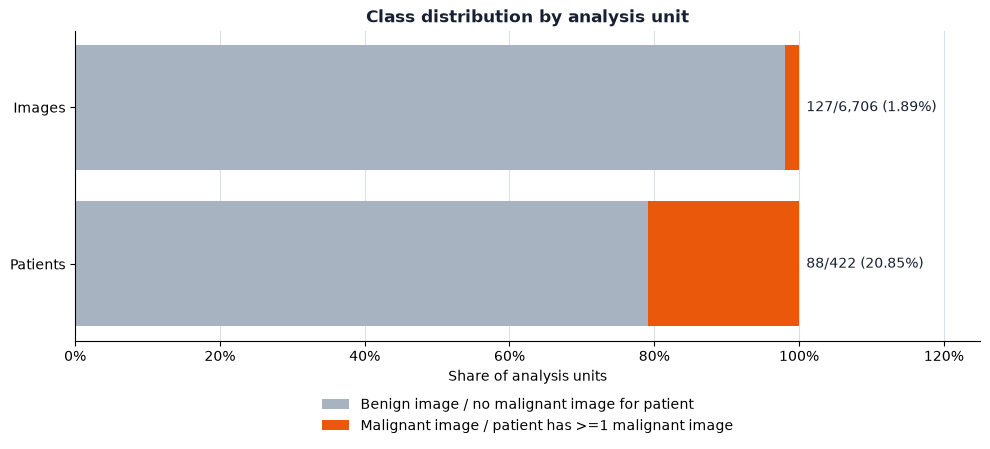

In [6]:
BLUE = "#2563EB"
ORANGE = "#EA580C"
GOLD = "#D4A72C"
INK = "#172033"
GRID = "#D9E0EA"
NEUTRAL = "#A8B3C2"

negative_share = 1 - grain_comparison["malignancy_rate"]
positive_share = grain_comparison["malignancy_rate"]
positions = np.arange(len(grain_comparison))

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(
    positions,
    negative_share,
    color=NEUTRAL,
    label="Benign image / no malignant image for patient",
)
ax.barh(
    positions,
    positive_share,
    left=negative_share,
    color=ORANGE,
    label="Malignant image / patient has >=1 malignant image",
)
ax.set_yticks(positions, grain_comparison["analysis_unit"])
ax.invert_yaxis()
ax.set_title("Class distribution by analysis unit", loc="center", color=INK, weight="bold")
ax.set_xlabel("Share of analysis units")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlim(0, 1.25)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

for position, row in grain_comparison.iterrows():
    ax.text(
        1.01,
        position,
        f"{int(row['positive']):,}/{int(row['total']):,} ({row['malignancy_rate']:.2%})",
        va="center",
        color=INK,
    )

ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, -0.34), ncol=1)
plt.tight_layout()
finish_figure(fig, "class_balance_images_patients")

### How many images does each patient contribute?

Read the histogram from left to right: the horizontal axis is the number of images recorded for one patient, and the height of each blue bar is the number of patients within that range. The orange dashed line marks the median, where half the patients have no more than that many images.

The figure shows whether a few patients contribute many more rows than others. A long tail to the right means that image-level results give those patients more weight. There is no better or worse bar height here; the purpose is to understand the records and plan evaluation.

Images per patient quantiles:
0.00      3.00
0.25      5.00
0.50     12.00
0.75     21.00
0.90     34.00
0.95     40.00
0.99     88.01
1.00    115.00


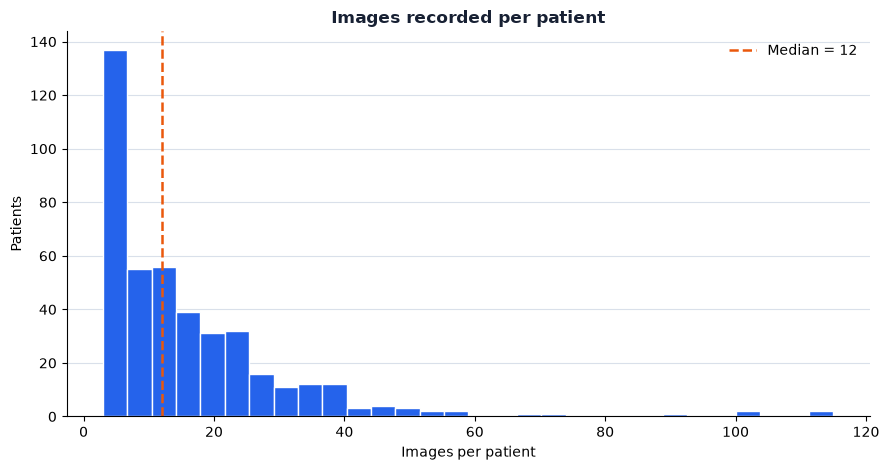

In [7]:
patient_quantiles = patient_summary["image_count"].quantile(
    [0, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 1]
)
print("Images per patient quantiles:")
print(patient_quantiles.to_string())

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.hist(patient_summary["image_count"], bins=30, color=BLUE, edgecolor="white")
ax.axvline(
    patient_summary["image_count"].median(),
    color=ORANGE,
    linestyle="--",
    linewidth=1.8,
    label=f"Median = {patient_summary['image_count'].median():.0f}",
)
ax.set_title("Images recorded per patient", loc="center", color=INK, weight="bold")
ax.set_xlabel("Images per patient")
ax.set_ylabel("Patients")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
finish_figure(fig, "images_per_patient")


### Compare sex, age and anatomical site

We calculate each category twice: once using all image rows and once counting a patient only once within that category. A patient is positive within a category if at least one of their images in that category is malignant.

Patients can appear in several age or site categories, so the category patient counts may add up to more than the total number of people. The diagnostic table reports how often this happens. These patient-category rates are descriptive checks; the models later predict the outcome of an individual image.

Deduplication does not collapse a patient's distinct photographs or force them into one age or site category. The same original within-category counting rule remains, making the clean figures directly comparable with the historical figures.

In [8]:
def ordered_age_categories(values: pd.Series) -> list[str]:
    unique_values = [str(value) for value in values.dropna().unique()]
    unknown_values = sorted(
        value for value in unique_values if value.casefold() == "unknown"
    )
    known_values = sorted(
        (value for value in unique_values if value.casefold() != "unknown"),
        key=lambda value: int(value),
    )
    return [*known_values, *unknown_values]


def summarise_feature(
    frame: pd.DataFrame,
    feature: str,
    order: list[str] | None = None,
) -> pd.DataFrame:
    image_summary = frame.groupby(feature, dropna=False)["target"].agg(
        image_count="size",
        malignant_images="sum",
        image_malignancy_rate="mean",
    )

    # One record per patient-category. A patient is positive in a category when
    # at least one of their images in that category is malignant.
    patient_category = (
        frame.groupby(["patient_id", feature], dropna=False, as_index=False)["target"]
        .max()
    )
    patient_summary_by_feature = patient_category.groupby(feature, dropna=False)["target"].agg(
        patient_count="size",
        malignant_patients="sum",
        patient_malignancy_rate="mean",
    )

    summary = image_summary.join(patient_summary_by_feature, how="outer")
    if order is not None:
        summary = summary.reindex(order)
    else:
        summary = summary.sort_values("image_count", ascending=False)

    summary["image_share"] = summary["image_count"] / summary["image_count"].sum()
    summary["patient_membership_share"] = (
        summary["patient_count"] / summary["patient_count"].sum()
    )
    summary["rate_difference_pp"] = 100 * (
        summary["patient_malignancy_rate"] - summary["image_malignancy_rate"]
    )
    return summary


features = ["sex", "age_approx", "anatom_site_general_challenge"]
patient_category_diagnostics = pd.DataFrame(
    {
        "patients": [train["patient_id"].nunique()] * len(features),
        "patients_in_multiple_categories": [
            int(train.groupby("patient_id")[feature].nunique().gt(1).sum())
            for feature in features
        ],
    },
    index=features,
)
print("Patients represented in multiple categories:")
print(patient_category_diagnostics.to_string())

feature_summaries = {
    "sex": summarise_feature(train, "sex"),
    "age_approx": summarise_feature(
        train,
        "age_approx",
        ordered_age_categories(train["age_approx"]),
    ),
    "anatom_site_general_challenge": summarise_feature(
        train,
        "anatom_site_general_challenge",
    ),
}

for feature, summary in feature_summaries.items():
    print(f"\n{feature}")
    printable = summary[
        [
            "image_count",
            "patient_count",
            "malignant_images",
            "malignant_patients",
            "image_malignancy_rate",
            "patient_malignancy_rate",
            "rate_difference_pp",
        ]
    ].copy()
    printable["image_malignancy_rate"] = printable["image_malignancy_rate"].map(
        lambda value: f"{value:.2%}"
    )
    printable["patient_malignancy_rate"] = printable["patient_malignancy_rate"].map(
        lambda value: f"{value:.2%}"
    )
    printable["rate_difference_pp"] = printable["rate_difference_pp"].map(
        lambda value: f"{value:+.2f}"
    )
    print(printable.to_string())


Patients represented in multiple categories:
                               patients  patients_in_multiple_categories
sex                                 422                                0
age_approx                          422                              204
anatom_site_general_challenge       422                              388

sex
        image_count  patient_count  malignant_images  malignant_patients image_malignancy_rate patient_malignancy_rate rate_difference_pp
sex                                                                                                                                      
female         3477            204                53                  37                 1.52%                  18.14%             +16.61
male           3229            218                74                  51                 2.29%                  23.39%             +21.10

age_approx
            image_count  patient_count  malignant_images  malignant_patients image_malignancy_

### Read the sex, age and site figures

Each figure has categories on the vertical axis. Blue bars represent image records; gold bars represent patients counted once within each category.

- **Left panel: category share.** The horizontal axis shows how much of the collection belongs to that category. Gold shares divide by all patient-category memberships, so a person recorded in several categories contributes to each. Compare blue and gold to see the effect of repeated images.
- **Right panel: malignant percentage.** The horizontal axis shows the malignant share within the category. Gold counts a patient as positive if any image in that category is malignant. Longer bars mean a higher observed rate, rather than a better or more certain result.

Use the sex figure to compare recorded groups, age to look across five-year buckets, and site to compare image locations. Check case counts before interpreting large rates in small groups. These views do not adjust for other characteristics or show confidence intervals, and their percentage scales differ.


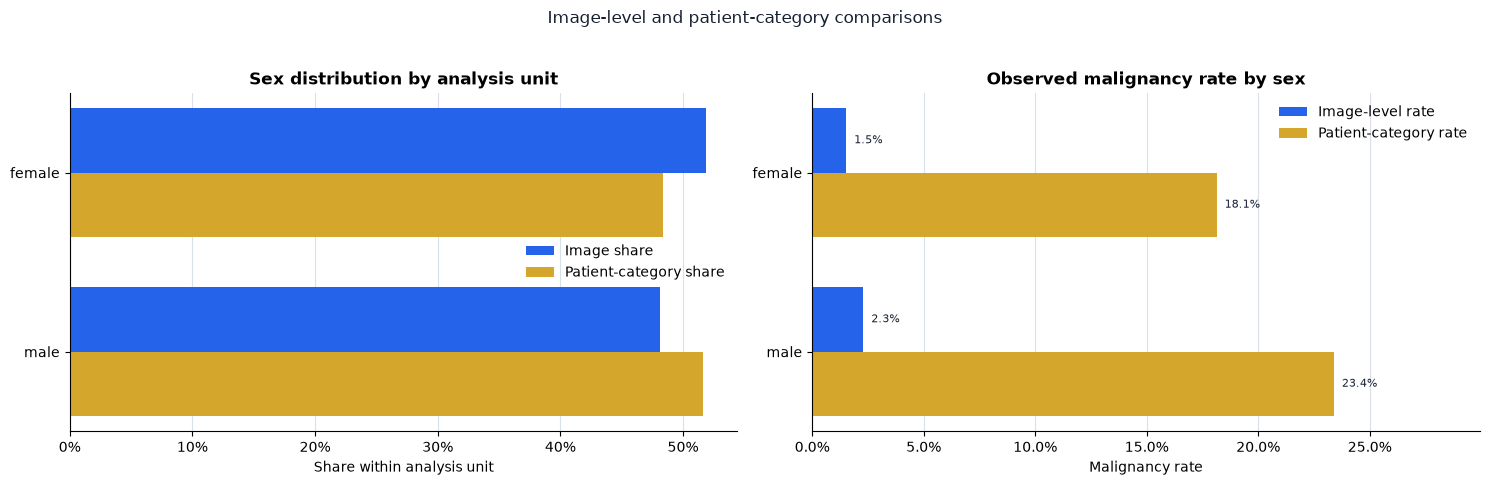

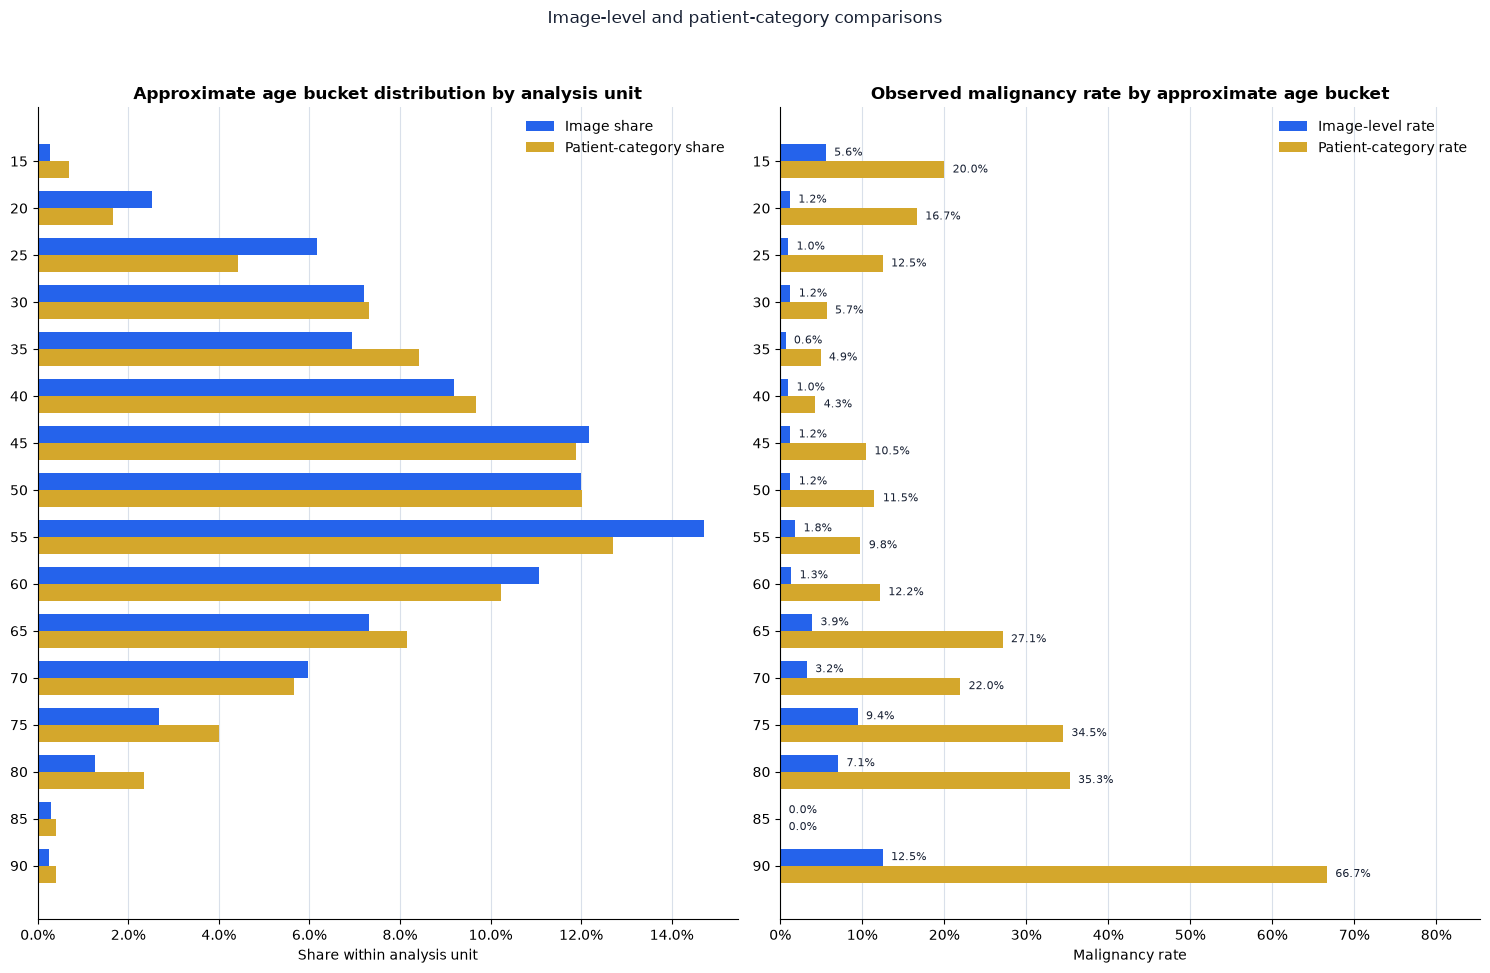

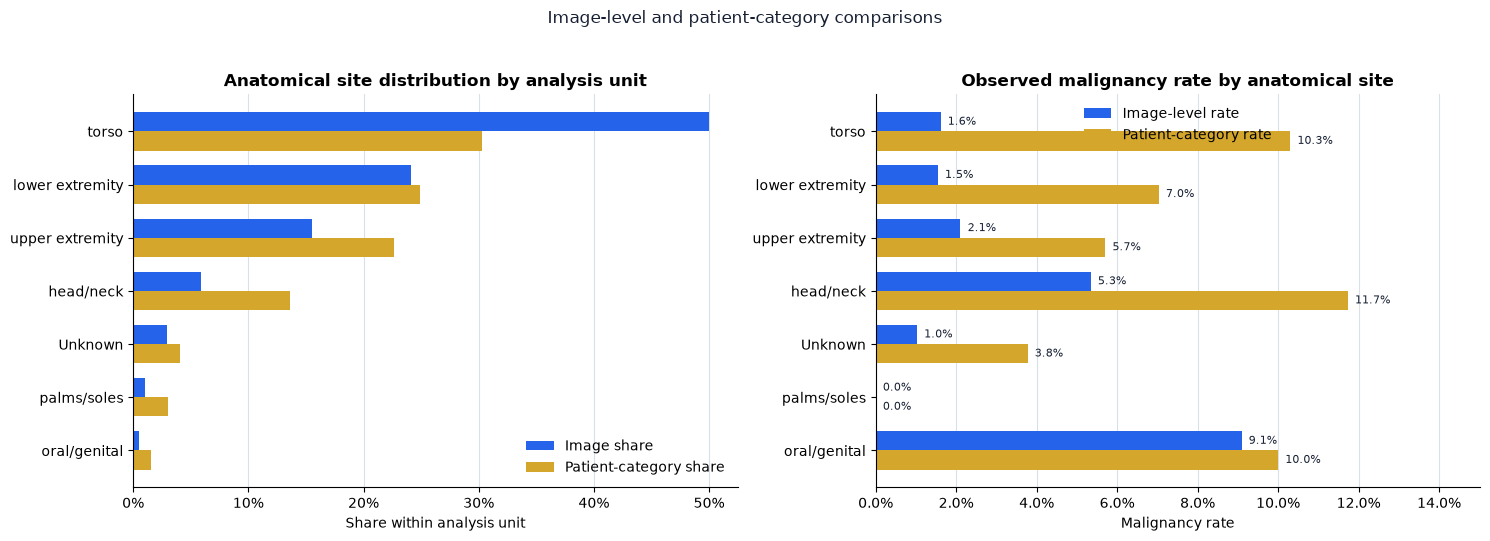

In [9]:
FEATURE_LABELS = {
    "sex": "Sex",
    "age_approx": "Approximate age bucket",
    "anatom_site_general_challenge": "Anatomical site",
}


def plot_feature_summary(feature: str, summary: pd.DataFrame) -> None:
    labels = summary.index.astype(str)
    positions = np.arange(len(summary))
    bar_height = 0.36
    height = max(4.8, 0.48 * len(summary) + 2.0)
    fig, axes = plt.subplots(1, 2, figsize=(15, height))

    axes[0].barh(
        positions - bar_height / 2,
        summary["image_share"],
        height=bar_height,
        color=BLUE,
        label="Image share",
    )
    axes[0].barh(
        positions + bar_height / 2,
        summary["patient_membership_share"],
        height=bar_height,
        color=GOLD,
        label="Patient-category share",
    )
    axes[0].set_yticks(positions, labels)
    axes[0].invert_yaxis()
    axes[0].set_title(
        f"{FEATURE_LABELS[feature]} distribution by analysis unit",
        loc="center",
        weight="bold",
    )
    axes[0].set_xlabel("Share within analysis unit")
    axes[0].xaxis.set_major_formatter(PercentFormatter(1.0))
    axes[0].legend(frameon=False)

    axes[1].barh(
        positions - bar_height / 2,
        summary["image_malignancy_rate"],
        height=bar_height,
        color=BLUE,
        label="Image-level rate",
    )
    axes[1].barh(
        positions + bar_height / 2,
        summary["patient_malignancy_rate"],
        height=bar_height,
        color=GOLD,
        label="Patient-category rate",
    )
    axes[1].set_yticks(positions, labels)
    axes[1].invert_yaxis()
    axes[1].set_title(
        f"Observed malignancy rate by {FEATURE_LABELS[feature].lower()}",
        loc="center",
        weight="bold",
    )
    axes[1].set_xlabel("Malignancy rate")
    axes[1].xaxis.set_major_formatter(PercentFormatter(1.0))
    axes[1].legend(frameon=False)

    rate_limit = max(
        summary[["image_malignancy_rate", "patient_malignancy_rate"]].max().max() * 1.28,
        0.03,
    )
    axes[1].set_xlim(0, rate_limit)
    for position, (_, row) in enumerate(summary.iterrows()):
        for offset, column in [
            (-bar_height / 2, "image_malignancy_rate"),
            (bar_height / 2, "patient_malignancy_rate"),
        ]:
            axes[1].text(
                row[column] + rate_limit * 0.012,
                position + offset,
                f"{row[column]:.1%}",
                va="center",
                fontsize=8,
                color=INK,
            )

    for ax in axes:
        ax.grid(axis="x", color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)

    fig.suptitle(
        "Image-level and patient-category comparisons",
        x=0.5,
        y=1.0,
        ha="center",
        color=INK,
    )
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    finish_figure(fig, {"sex": "sex_image_patient_share_rates",
        "age_approx": "age_image_patient_share_rates",
        "anatom_site_general_challenge": "site_image_patient_share_rates"}[feature])


for feature, summary in feature_summaries.items():
    plot_feature_summary(feature, summary)


### Check diagnosis labels

Read `image_count` as the number of records with each diagnosis, and `malignancy_rate` as the percentage of those images with target `1`. This table helps check how the diagnosis labels relate to the recorded outcome.

Diagnosis and the benign/malignant description must stay out of model inputs. The melanoma diagnosis already identifies the target, so giving it to a prediction model would reveal the answer. An `unknown` diagnosis describes the detail available in this file; it does not mean the image's target is missing.

In [10]:
diagnosis_summary = (
    train.groupby("diagnosis")["target"]
    .agg(image_count="size", malignant_images="sum", malignancy_rate="mean")
    .sort_values("image_count", ascending=False)
)
diagnosis_summary["malignancy_rate"] = diagnosis_summary["malignancy_rate"].map(
    lambda value: f"{value:.2%}"
)
print(diagnosis_summary.to_string())


                      image_count  malignant_images malignancy_rate
diagnosis                                                          
unknown                      5421                 0           0.00%
nevus                        1107                 0           0.00%
melanoma                      127               127         100.00%
seborrheic keratosis           27                 0           0.00%
lichenoid keratosis            14                 0           0.00%
lentigo NOS                     8                 0           0.00%
cafe-au-lait macule             1                 0           0.00%
solar lentigo                   1                 0           0.00%


## Document retained category support

**Added deduplication context.** The original category figures show unadjusted rates. For a sparse group such as unknown site, read malignant-image and malignant-patient counts before making a subgroup claim. Removing exact copies does not resolve missing information, differing collection conditions or patients with several recorded ages. The saved audit table below documents retained support by fold and label; it does not choose predictors or exclude observations.

In [11]:
show_saved_table("results/dedup_v1/audit/missing_site_by_fold_label_retained.csv")
profiles = pd.read_csv(ROOT / "results/dedup_v1/audit/patient_profile_retained.csv")
display(pd.DataFrame([{"patients_multiple_ages": int(profiles.distinct_ages.gt(1).sum()),
    "patients_age_span_at_least_15": int(profiles.age_span.ge(15).sum())}]))

,fold,target,site_missing,images,patients
0,0,0,False,1287,84
1,0,0,True,33,15
2,0,1,False,23,16
3,0,1,True,1,1
4,1,0,False,1331,84
5,1,0,True,9,7
6,1,1,False,26,15
7,2,0,False,1278,87
8,2,0,True,24,13
9,2,1,False,25,21


,patients_multiple_ages,patients_age_span_at_least_15
0,204,41


## Limitations

These patterns describe the supplied training collection. They cannot establish causes of melanoma, a person's clinical risk, or performance on new patients. Differences between categories may also reflect age, site, sex or sampling differences that these separate tables do not adjust for.

Multiple images from one person are related. Image-level percentages give people with more images more weight, and patient-category counts can include the same person in several categories. Small groups can show large percentages after only a few malignant cases; the figures do not show confidence intervals. Unknown labels keep missing information visible but do not correct its possible bias.

Filename and record checks cannot confirm image quality, clinically correct labels, or the absence of visually similar but distinct images. No prediction model is trained or evaluated here.

The exact-copy audit removes repeated identical pixels only. Related photographs and sampling differences remain, so the later patient-grouped validation and patient-bootstrap intervals are still necessary.

## Summary

The saved clean run describes 6,706 retained images from 422 patients. Malignancy accounts for 1.89% of images; 20.85% of patients have at least one malignant image. Patients contribute a median of 12 images and a maximum of 115. The retained record checks find no missing cells, duplicate image names or target inconsistencies.

Compared with the original 6,864-image collection, 158 confirmed exact copies are excluded while all 422 patients remain. The blue/gold category panels, orange/grey class-balance figure and patient histogram use the original colours, dimensions, labels and counting rules with clean counts.

Age, sex and site remain candidate predictors; diagnosis and the benign/malignant description must stay out of model inputs. Repeated distinct images and the different counting units support grouping by patient. Next, [03_patient_fold_verification.ipynb](03_patient_fold_verification.ipynb) verifies the shared historical evaluation folds after retention, rather than creating replacement groups.